# Class Quiz
### Guideline
1. Please submit the file via Google Classroom.
2. File name convention is MSA38DN_\<Your full name\>\_classquizN
3. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

In [2]:
# Libraries

import os
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import requests

In [3]:
download_url = "https://i.pinimg.com/1200x/ab/53/ca/ab53cab7e9784f2f5794f96cee7d5f1d.jpg"
img_gray = None

# Requirements
Following in-class instructions



In [4]:
# 1. Download image data from the URL and convert it to grayscale

def download_input_data(url):
    print(f"Downloading from {url}")

    response = requests.get(url, stream=True)
    response.raise_for_status()
    image_data = np.asarray(bytearray(response.content), dtype="uint8")
    img_gray = cv.imdecode(image_data, cv.IMREAD_GRAYSCALE)

    return img_gray


def print_basic_properties(img_data):
    print(f"Shape: {img_data.shape}")
    print(f"Data type: {img_data.dtype}")
    print(f"Minimum pixel value: {np.min(img_data)}")
    print(f"Maximum pixel value: {np.max(img_data)}")

In [5]:
# 2. Read image as matrix A

if img_gray is None:
    img_gray = download_input_data(download_url)

A = np.copy(img_gray)

print("Matrix A:")
print(A)

print_basic_properties(A)

Matrix A:
[[75 75 75 ... 34 33 33]
 [76 76 76 ... 34 33 33]
 [76 76 76 ... 34 33 33]
 ...
 [83 82 81 ... 21 21 20]
 [82 81 81 ... 21 21 20]
 [81 81 80 ... 21 21 20]]
Shape: (798, 1198)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 236


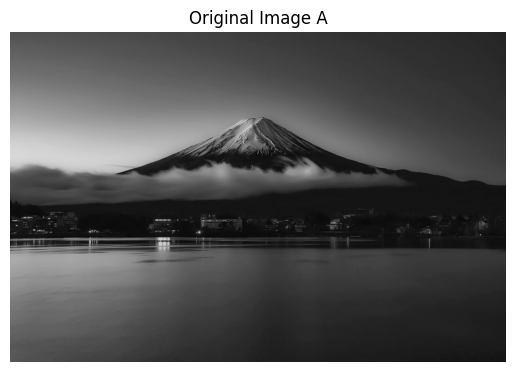

In [6]:
# 3. Display original image
plt.imshow(A, cmap='gray')
plt.title("Original Image A")
plt.axis('off')
plt.show()

Matrix B (flipped horizontally):
[[33 33 34 ... 75 75 75]
 [33 33 34 ... 76 76 76]
 [33 33 34 ... 76 76 76]
 ...
 [20 21 21 ... 81 82 83]
 [20 21 21 ... 81 81 82]
 [20 21 21 ... 80 81 81]]
Shape of B: (798, 1198)


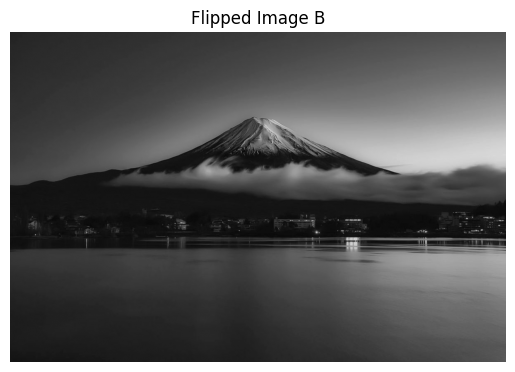

In [7]:
# 4. Create matrix B by flipping A horizontally

B = np.fliplr(A)

print("Matrix B (flipped horizontally):")
print(B)

print("Shape of B:", B.shape)

plt.imshow(B, cmap='gray')
plt.title("Flipped Image B")
plt.axis('off')
plt.show()

Matrix A after replacing odd rows:
[[75 75 75 ... 34 33 33]
 [33 33 34 ... 76 76 76]
 [76 76 76 ... 34 33 33]
 ...
 [20 21 21 ... 81 82 83]
 [82 81 81 ... 21 21 20]
 [20 21 21 ... 80 81 81]]
Shape of A: (798, 1198)


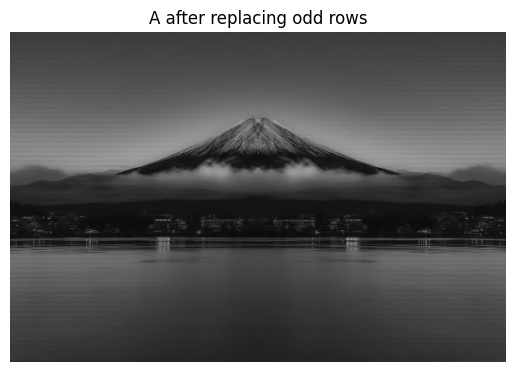

In [8]:
# 5. Replace the odd rows from matrix A by the matrix B.

A[1::2] = B[1::2]

print("Matrix A after replacing odd rows:")
print(A)

print("Shape of A:", A.shape)

# Display updated image
plt.imshow(A, cmap='gray')
plt.title("A after replacing odd rows")
plt.axis('off')
plt.show()

Matrix A after deleting even columns:
[[75 75 75 ... 34 34 33]
 [33 34 34 ... 76 76 76]
 [76 76 76 ... 34 34 33]
 ...
 [20 21 20 ... 80 80 82]
 [82 81 80 ... 19 20 21]
 [20 21 20 ... 80 80 81]]
New shape of A: (798, 599)


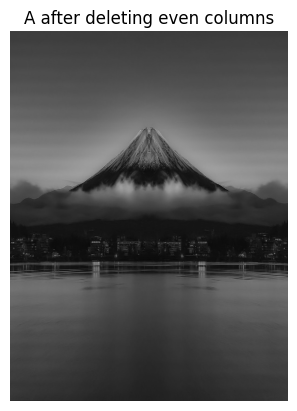

In [9]:
# 6. Delete the even columns from matrix A.

A = np.delete(A, np.s_[1::2], axis=1)

print("Matrix A after deleting even columns:")
print(A)

print("New shape of A:", A.shape)

# Display updated image
plt.imshow(A, cmap='gray')
plt.title("A after deleting even columns")
plt.axis('off')
plt.show()

Shape: (256, 256)
Data type: uint8
Minimum pixel value: 5
Maximum pixel value: 218


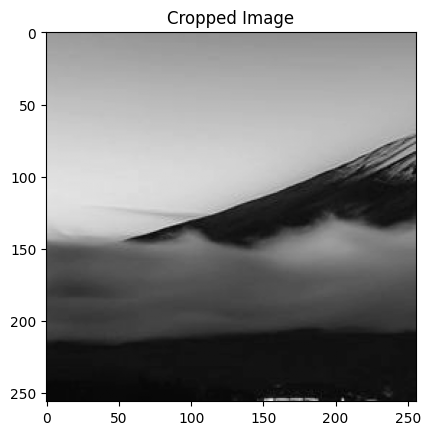

In [10]:
# 7. Crop image

start_point = [200, 200]
size = 256

img_crop = img_gray[
    start_point[0]:start_point[0] + size,
    start_point[1]:start_point[1] + size
]

print_basic_properties(img_crop)

plt.imshow(img_crop, cmap='gray')
plt.title("Cropped Image")
plt.axis('on')
plt.show()

Shape: (798, 1198)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 250


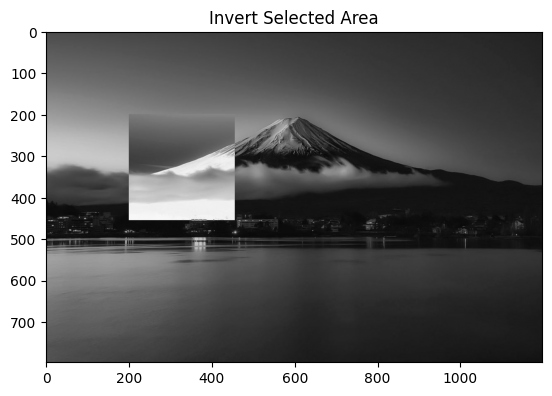

In [11]:
# 8. Invert selected area

start_point = [200, 200]
size = 256

img_clone = np.copy(img_gray)

img_clone[
    start_point[0]:start_point[0] + size,
    start_point[1]:start_point[1] + size
] = 255 - img_clone[
    start_point[0]:start_point[0] + size,
    start_point[1]:start_point[1] + size
]

print_basic_properties(img_clone)

plt.imshow(img_clone, cmap='gray')
plt.title("Invert Selected Area")
plt.axis('on')
plt.show()

Shape: (798, 1198)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 222


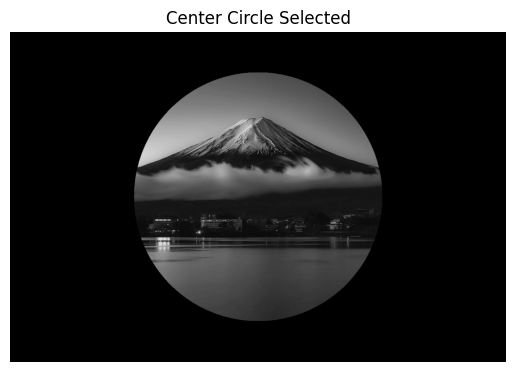

In [12]:
# 9. Create circular mask

h, w = img_gray.shape

center_x = w // 2
center_y = h // 2

radius = 300

mask = np.zeros_like(img_gray)

cv.circle(mask, (center_x, center_y), radius, (255), -1)

img_center_circle = np.bitwise_and(img_gray, mask)

print_basic_properties(img_center_circle)

plt.imshow(img_center_circle, cmap='gray')
plt.title("Center Circle Selected")
plt.axis('off')
plt.show()

Shape: (798, 2396)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 236


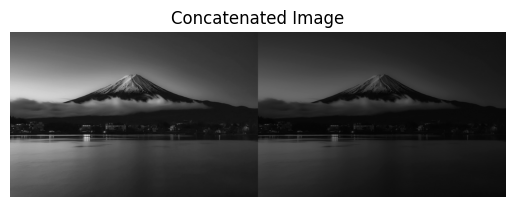

In [13]:
# 10. Concatenate images

img_temp = img_gray // 2

img_concat = np.concatenate((img_gray, img_temp), axis=1)

print_basic_properties(img_concat)

plt.imshow(img_concat, cmap='gray')
plt.title("Concatenated Image")
plt.axis('off')
plt.show()